# 01 - General overview of the corpus

What is in the data, how complete is it, and what does it look like? Run this notebook first.

* Data: the exports in `storage/raw/` (set `TG_DATA` to use another folder). Older exports of the same channel are
  merged, duplicate posts dropped.
* All days / hours are **Europe/Berlin** time (the database stores UTC).
* Every figure is also saved in `storage/figures/`.

In [1]:
%matplotlib inline
import os, warnings
from datetime import date, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

from tg_ingestor.analysis import *

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

DATA = os.environ.get("TG_DATA", "../storage/raw")            # folder with the exported .csv / .parquet files
FIG = Path(os.environ.get("TG_FIGURES", "../storage/figures"))  # every plot / table is also saved here
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.25})
pl.Config.set_tbl_rows(40).set_tbl_cols(20).set_fmt_str_lengths(70)


def savefig(name):
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")

In [2]:
df = load_corpus(DATA)
print(f"{df.height:,} posts | {df['channel'].n_unique()} channels | {df['day'].min()} .. {df['day'].max()}")
print(f"{len(reaction_columns(df))} reaction columns, {len(df.columns)} columns loaded")
df.select("channel", "id", "ts", "text", "views", "forwards", "media_kind", "has_text").head(5)

869,307 posts | 19 channels | 2020-01-01 .. 2026-10-21
73 reaction columns, 154 columns loaded


channel,id,ts,text,views,forwards,media_kind,has_text
str,i64,"datetime[μs, Europe/Berlin]",str,i64,i64,str,bool
"""AllesAusserMainstream""",4,2020-07-08 22:38:14 CEST,"""https://t.me/QUERDENKEN_711/339""",66202,37,"""WEB_PAGE""",true
"""AllesAusserMainstream""",5,2020-07-08 22:40:05 CEST,"""https://youtu.be/SW3YYQQhOZM""",69232,367,"""TEXT_ONLY""",true
"""AllesAusserMainstream""",6,2020-07-08 22:40:27 CEST,"""https://youtu.be/9FhJh60XeHY""",93190,1492,"""TEXT_ONLY""",true
"""AllesAusserMainstream""",7,2020-07-08 22:49:38 CEST,"""https://youtu.be/GySTaENpCRU""",11565,66,"""TEXT_ONLY""",true
"""AllesAusserMainstream""",8,2020-07-09 07:49:39 CEST,"""https://youtu.be/pkPrXpS_dis""",11109,7,"""TEXT_ONLY""",true


## 1. Channels at a glance

In [3]:
overview = (
    df.group_by("channel").agg(
        pl.len().alias("posts"),
        pl.col("day").min().alias("first_post"),
        pl.col("day").max().alias("last_post"),
        pl.col("has_text").mean().round(3).alias("share_with_text"),
        (pl.col("media_kind") != "TEXT_ONLY").mean().round(3).alias("share_with_media"),
        pl.col("is_forward").mean().round(3).alias("share_forwarded"),
        pl.col("views").median().alias("median_views"),
        pl.col("forwards").median().alias("median_forwards"),
        pl.col("n_words").median().alias("median_words"),
    )
    .with_columns(((pl.col("last_post") - pl.col("first_post")).dt.total_days() + 1).alias("span_days"))
    .with_columns((pl.col("posts") / pl.col("span_days")).round(2).alias("posts_per_day"))
    .sort("posts", descending=True)
)
overview.write_csv(FIG / "channel_overview.csv")
overview

channel,posts,first_post,last_post,share_with_text,share_with_media,share_forwarded,median_views,median_forwards,median_words,span_days,posts_per_day
str,u32,date,date,f64,f64,f64,f64,f64,f64,i64,f64
"""EvaHermanOffiziell""",224481,2020-01-01,2026-10-21,0.911,0.935,0.214,34375.0,110.0,66.0,2486,90.3
"""oliverjanich""",149281,2020-01-01,2026-10-21,0.917,0.842,0.652,26080.0,120.0,37.0,2486,60.05
"""DruschbaFM""",84134,2020-11-24,2026-10-21,0.773,0.903,0.115,5119.0,11.0,50.0,2158,38.99
"""epochtimesde""",78228,2020-01-01,2026-10-20,0.999,0.982,0.005,5000.5,12.0,45.0,2485,31.48
"""satellit_de""",71143,2022-03-14,2026-10-21,0.723,0.783,0.034,7060.0,24.0,70.0,1683,42.27
"""AllesAusserMainstream""",49440,2020-07-08,2026-10-21,0.822,0.819,0.707,46109.5,277.0,27.0,2297,21.52
"""CompactMagazin""",44180,2020-01-01,2026-10-20,0.957,0.949,0.094,11817.0,28.0,45.0,2485,17.78
"""neuesausrussland""",30560,2021-11-05,2026-10-20,0.623,0.828,0.218,54887.0,154.0,36.0,1811,16.87
"""rt_de_live""",29218,2023-06-08,2026-10-21,1.0,0.926,0.0,238.0,0.0,28.0,1232,23.72


## 2. Completeness check

Long gaps with no post at all are either genuine pauses, deleted history, or an incomplete download.
The channels' first posts also show when each channel starts (a channel that starts in 2022 says nothing about 2020 -
later notebooks only count a channel from its first post on).

In [4]:
gaps = (
    df.select("channel", "day").unique().sort("channel", "day")
    .with_columns((pl.col("day") - pl.col("day").shift(1).over("channel")).dt.total_days().alias("gap_days"))
    .filter(pl.col("gap_days") > 14)
    .with_columns(pl.col("day").alias("gap_ends"), (pl.col("day") - pl.duration(days=pl.col("gap_days"))).alias("gap_starts"))
    .select("channel", "gap_starts", "gap_ends", "gap_days").sort("gap_days", descending=True)
)
print(f"{gaps.height} gaps longer than 14 days")
gaps.head(20)

35 gaps longer than 14 days


channel,gap_starts,gap_ends,gap_days
str,date,date,i64
"""icic_law_official""",2024-07-31,2025-12-23,510
"""RKI_Files""",2026-01-28,2026-10-09,254
"""Dr_Reiner_Fuellmich""",2022-02-12,2022-09-13,213
"""icic_law_official""",2024-01-13,2024-05-16,124
"""RKI_Files""",2025-05-26,2025-09-08,105
"""RKI_Files""",2025-10-31,2026-01-28,89
"""icic_law_official""",2024-05-16,2024-07-31,76
"""NachDenkSeiten_DE""",2021-05-01,2021-07-07,67
"""icic_law_official""",2023-11-12,2024-01-13,62


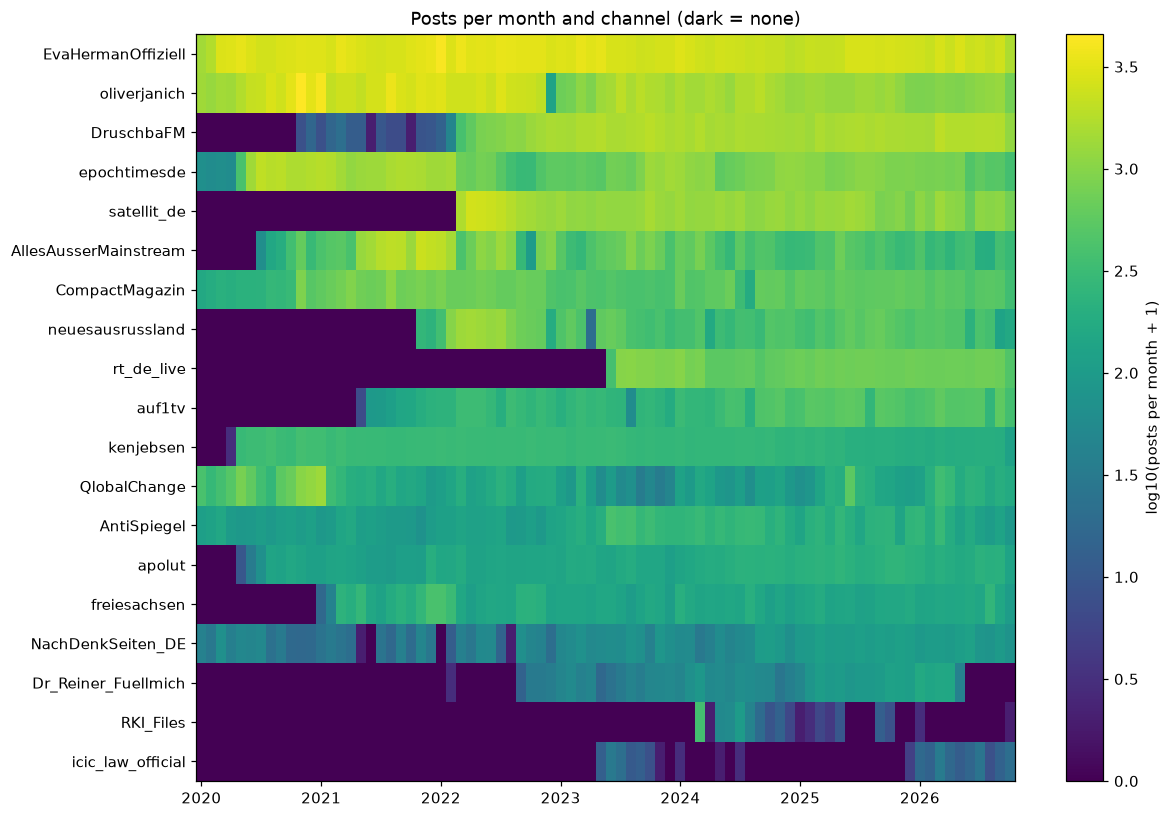

In [5]:
order = overview["channel"].to_list()
m = (df.group_by("channel", "month").agg(pl.len().alias("n")).to_pandas()
       .pivot(index="channel", columns="month", values="n").fillna(0).loc[order])
fig, ax = plt.subplots(figsize=(12, 0.38 * len(m) + 1.6))
im = ax.imshow(np.log10(m.to_numpy() + 1), aspect="auto", cmap="viridis", interpolation="nearest")
ax.set_yticks(range(len(m)), m.index)
yrs = [i for i, c in enumerate(m.columns) if pd.Timestamp(c).month == 1]
ax.set_xticks(yrs, [pd.Timestamp(m.columns[i]).year for i in yrs])
ax.grid(False)
plt.colorbar(im, label="log10(posts per month + 1)")
ax.set_title("Posts per month and channel (dark = none)")
savefig("01_posts_per_month_heatmap"); plt.show()

## 3. Overall volume over time, with the periods and events from `config/`

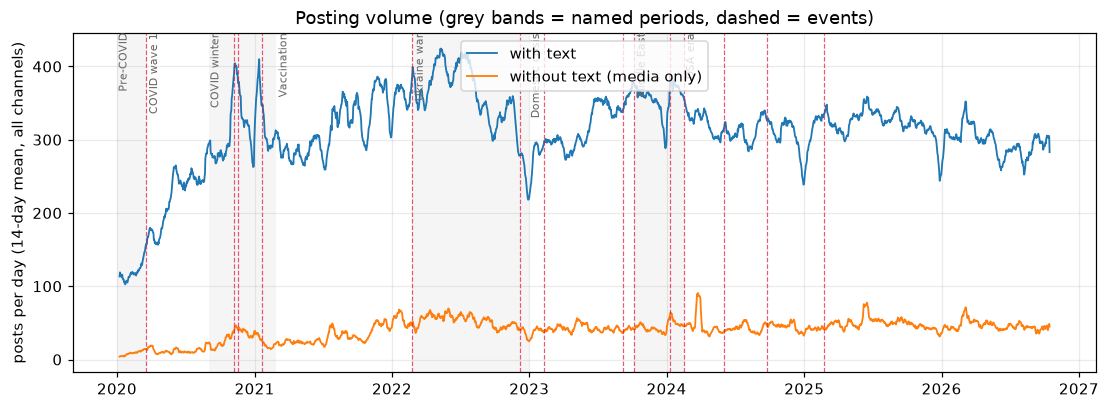

In [6]:
PHASES = load_phases(os.environ.get("TG_PHASES"))
EVENTS = load_events(os.environ.get("TG_EVENTS"))
daily = daily_counts(df, by=())
s_all = to_series(daily, "n"); s_text = to_series(daily, "n_text"); s_notext = to_series(daily, "n_notext")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(s_text.rolling(14, center=True).mean(), lw=1.2, label="with text")
ax.plot(s_notext.rolling(14, center=True).mean(), lw=1.2, label="without text (media only)")
ax.set_ylabel("posts per day (14-day mean, all channels)"); ax.legend(loc="upper center")
shade_phases(ax, PHASES); mark_events(ax, EVENTS)
ax.set_title("Posting volume (grey bands = named periods, dashed = events)")
savefig("01_volume_over_time"); plt.show()

## 4. What kind of posts?

`media_kind` is Telegram's media type (`TEXT_ONLY` = no attachment).

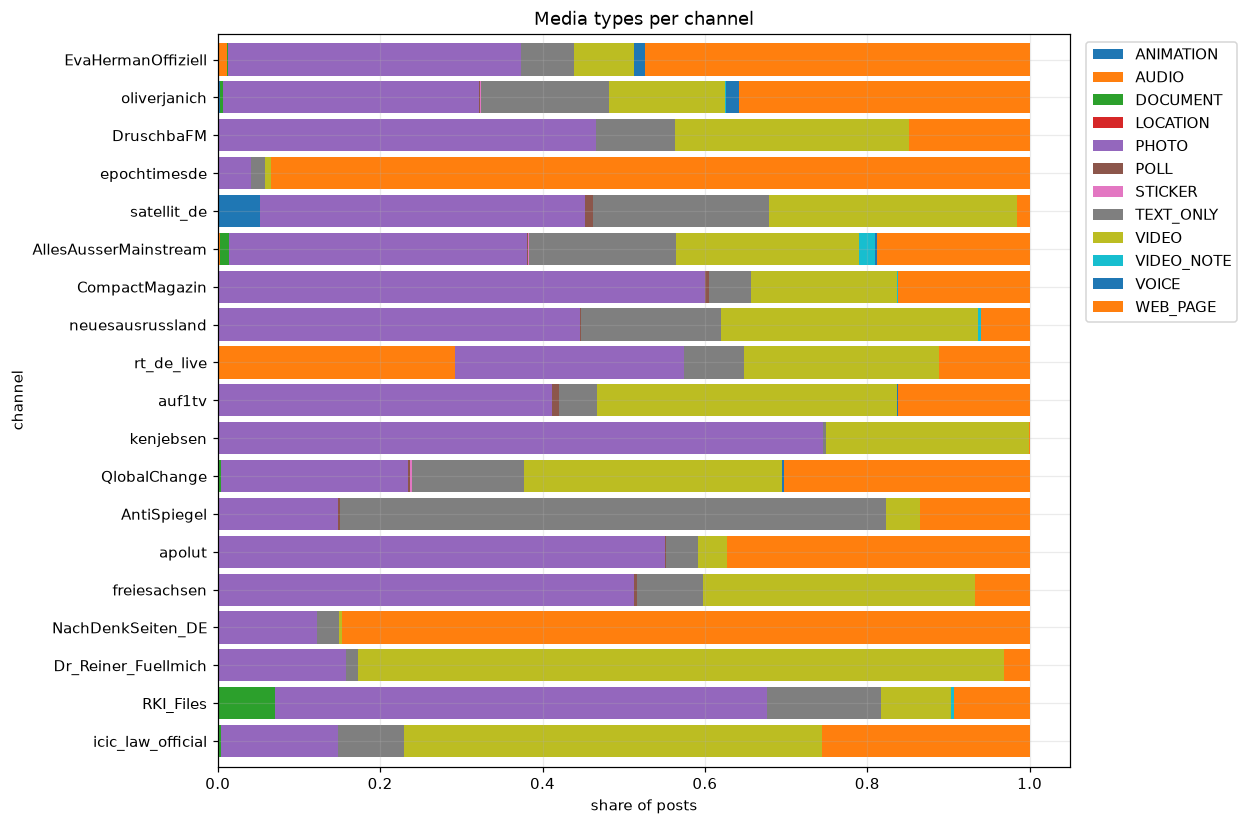

In [7]:
mk = (df.group_by("channel", "media_kind").len().to_pandas().pivot(index="channel", columns="media_kind", values="len").fillna(0))
mk = mk.div(mk.sum(axis=1), axis=0).loc[order[::-1]]
ax = mk.plot(kind="barh", stacked=True, figsize=(10, 0.35 * len(mk) + 2), width=0.85)
ax.set_xlabel("share of posts"); ax.set_title("Media types per channel"); ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
savefig("01_media_kinds"); plt.show()

## 5. Reach and engagement per post

Views, forwards and reactions are a **snapshot at download time** - old posts have had years to collect views.
Compare channels within the same period, not raw numbers across years.

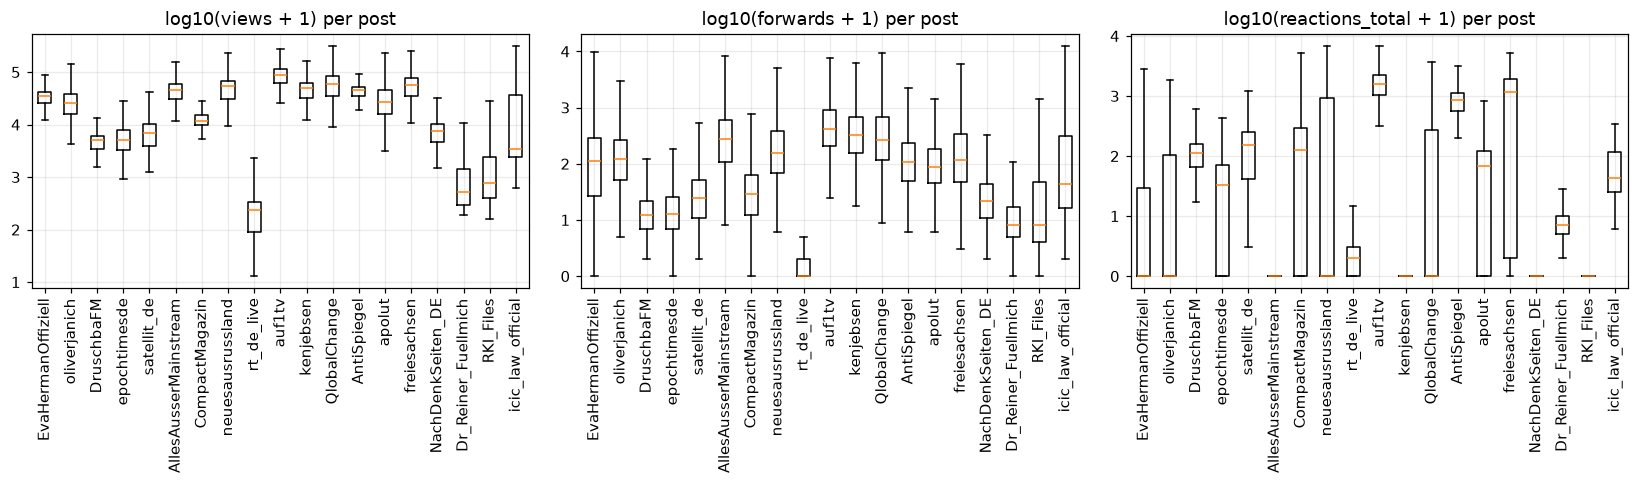

In [8]:
pdf = df.select("channel", "views", "forwards", "reactions_total").to_pandas()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, ["views", "forwards", "reactions_total"]):
    data = [np.log10(pdf.loc[pdf.channel == c, col].dropna() + 1) for c in order]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks(range(1, len(order) + 1), order, rotation=90)
    ax.set_title(f"log10({col} + 1) per post")
plt.tight_layout(); savefig("01_engagement_boxplots"); plt.show()

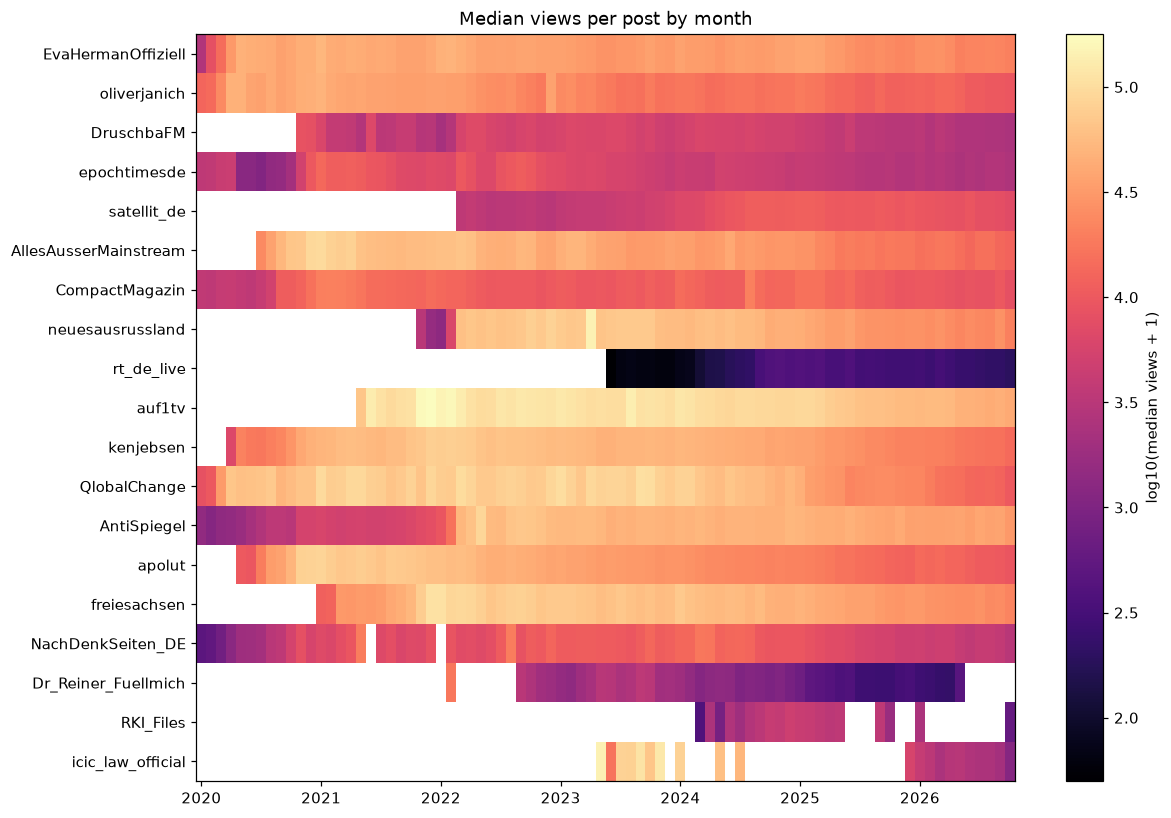

In [9]:
med = (df.group_by("channel", "month").agg(pl.col("views").median().alias("v")).to_pandas()
         .pivot(index="channel", columns="month", values="v").loc[order])
fig, ax = plt.subplots(figsize=(12, 0.38 * len(med) + 1.6))
im = ax.imshow(np.log10(med.to_numpy().astype(float) + 1), aspect="auto", cmap="magma", interpolation="nearest")
ax.set_yticks(range(len(med)), med.index)
yrs = [i for i, c in enumerate(med.columns) if pd.Timestamp(c).month == 1]
ax.set_xticks(yrs, [pd.Timestamp(med.columns[i]).year for i in yrs]); ax.grid(False)
plt.colorbar(im, label="log10(median views + 1)"); ax.set_title("Median views per post by month")
savefig("01_median_views_heatmap"); plt.show()

## 6. When do they post?

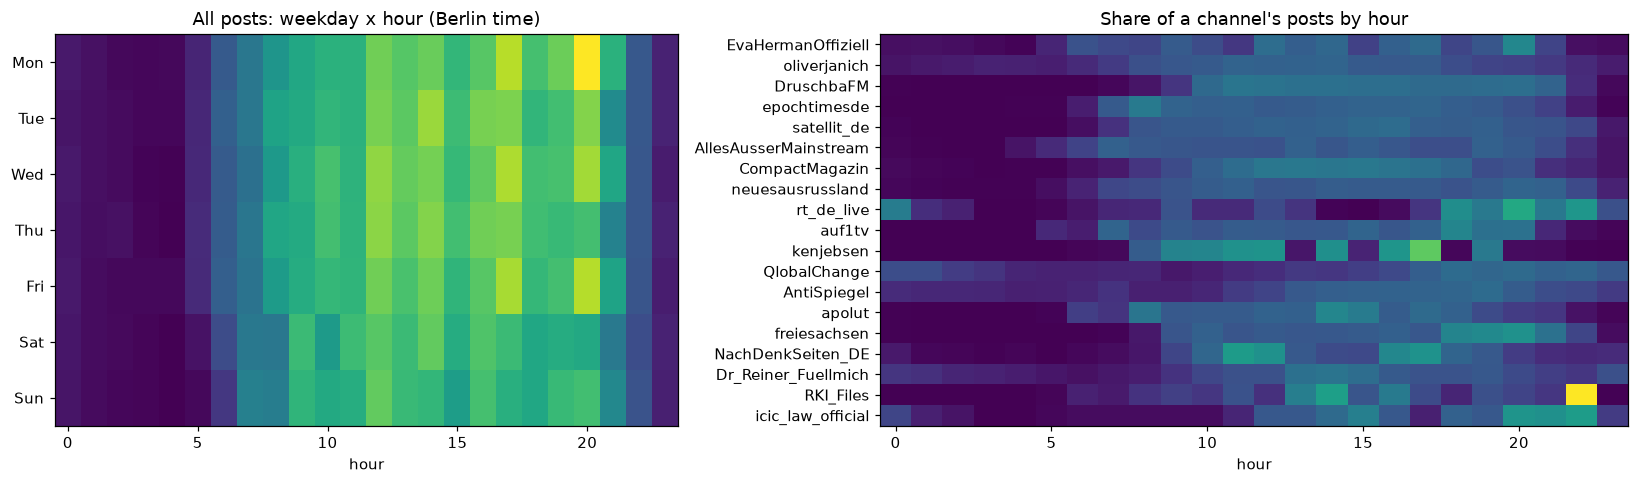

In [10]:
hw = df.group_by("weekday", "hour").len().to_pandas().pivot(index="weekday", columns="hour", values="len").fillna(0)
hw = hw.reindex(range(1, 8)).fillna(0)
ch = (df.group_by("channel", "hour").len().to_pandas().pivot(index="channel", columns="hour", values="len").fillna(0).reindex(order))
ch = ch.div(ch.sum(axis=1), axis=0)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 1.2]})
axes[0].imshow(hw.to_numpy(), aspect="auto", cmap="viridis"); axes[0].set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[0].set_title("All posts: weekday x hour (Berlin time)"); axes[0].set_xlabel("hour"); axes[0].grid(False)
axes[1].imshow(ch.to_numpy(), aspect="auto", cmap="viridis"); axes[1].set_yticks(range(len(ch)), ch.index)
axes[1].set_title("Share of a channel's posts by hour"); axes[1].set_xlabel("hour"); axes[1].grid(False)
plt.tight_layout(); savefig("01_posting_times"); plt.show()

## 7. Text: length, hashtags, linked domains

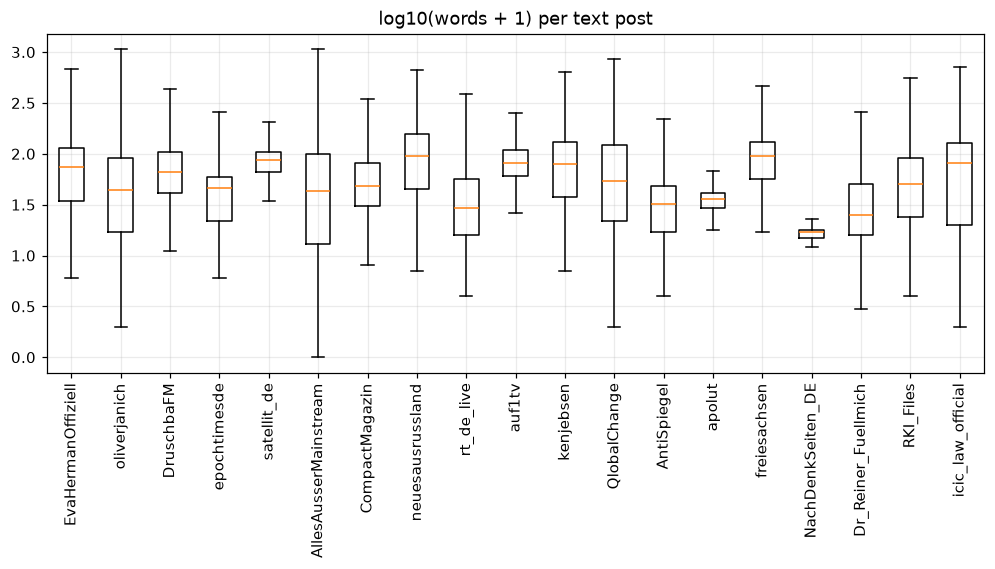

In [11]:
txt = df.filter(pl.col("has_text"))
fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot([np.log10(txt.filter(pl.col("channel") == c)["n_words"].to_numpy() + 1) for c in order], showfliers=False)
ax.set_xticks(range(1, len(order) + 1), order, rotation=90); ax.set_title("log10(words + 1) per text post")
savefig("01_text_length"); plt.show()

In [12]:
tags = (df.select("channel", pl.col("text").str.to_lowercase().str.extract_all(r"#\w+").alias("tag"))
          .explode("tag").drop_nulls())
top_tags = tags.group_by("tag").agg(pl.len().alias("posts"), pl.col("channel").n_unique().alias("channels")).sort("posts", descending=True).head(30)
top_tags

tag,posts,channels
str,u32,u32
"""#rt""",4392,3
"""#rtdeutsch""",4388,2
"""#rtde""",4387,1
"""#nachrichten""",4088,5
"""#tagesdosis""",1866,7
"""#deutschland""",1858,11
"""#standpunkte""",1703,7
"""#stabildurchdenwandel""",1568,2
"""#abendgebet""",1460,3


In [13]:
doms = (df.select("channel", pl.col("text").str.extract_all(r"https?://[^/\s]+").alias("u"))
          .explode("u").drop_nulls()
          .with_columns(pl.col("u").str.replace(r"^https?://(www\.)?", "").str.to_lowercase().alias("domain")))
print("links in total:", doms.height, "| share t.me:", round((doms["domain"] == "t.me").mean(), 3))
top_dom = doms.group_by("domain").agg(pl.len().alias("links"), pl.col("channel").n_unique().alias("channels")).sort("links", descending=True).head(30)
top_dom

links in total: 529014 | share t.me: 0.253


domain,links,channels
str,u32,u32
"""t.me""",134068,19
"""epochtimes.de""",46610,9
"""kopp-verlag.de""",41632,6
"""youtube.com""",20021,17
"""druschbafm.com""",13353,1
"""compact-online.de""",12813,10
"""youtu.be""",11020,17
"""x.com""",10375,15
"""bild.de""",10282,10


In [14]:
per_ch = (doms.filter(pl.col("domain") != "t.me").group_by("channel", "domain").len().sort("len", descending=True)
          .group_by("channel").head(3).sort("channel", "len", descending=[False, True]))
per_ch

channel,domain,len
str,str,u32
"""AllesAusserMainstream""","""youtube.com""",981
"""AllesAusserMainstream""","""youtu.be""",977
"""AllesAusserMainstream""","""tkp.at""",576
"""AntiSpiegel""","""anti-spiegel.ru""",2124
"""AntiSpiegel""","""youtube.com""",231
"""AntiSpiegel""","""kenfm.de""",48
"""CompactMagazin""","""compact-online.de""",11884
"""CompactMagazin""","""tinyurl.com""",2610
"""CompactMagazin""","""bit.ly""",2030


## 8. Forwarded posts

Which channels does each channel repost? (Needs the `forward_*` columns, present only where Telegram supplied them.)

In [15]:
cand = [c for c in ("forward_origin.chat.title", "forward_from_chat.title", "forward_origin.sender_user_name", "forward_sender_name") if c in df.columns]
print("columns with forward information:", [c for c in df.columns if c.startswith("forward_")][:12])
if cand:
    src = cand[0]
    fw = df.filter(pl.col(src).is_not_null()).group_by("channel", src).len().sort("len", descending=True).head(25)
    display(fw)
else:
    print("no forward-source column in this corpus")

columns with forward information: ['forward_date', 'forward_from.dc_id', 'forward_from.first_name', 'forward_from.id', 'forward_from.is_bot', 'forward_from.is_contact', 'forward_from.is_deleted', 'forward_from.is_fake', 'forward_from.is_mutual_contact', 'forward_from.is_premium', 'forward_from.is_restricted', 'forward_from.is_scam']


channel,forward_from_chat.title,len
str,str,u32
"""EvaHermanOffiziell""","""Eva Herman Offiziell""",36576
"""oliverjanich""","""Oliver Janich & Team""",7001
"""oliverjanich""","""Eva Herman Offiziell""",5843
"""oliverjanich""","""Der Waldgang""",3934
"""oliverjanich""","""Schuberts Lagemeldung - Stefan Schubert Offiziell""",3376
"""oliverjanich""","""1984 – Das Magazin""",3346
"""oliverjanich""","""Uncut-News.ch ""Das Original""🇨🇭Unabhängige Analysen und Informationen z…",3062
"""oliverjanich""","""henning rosenbusch - Channel""",3026
"""oliverjanich""","""Report24.news""",2425


## Notes
* `share_forwarded` counts posts with any `forward_*` information. `forwards` (a number) is how often *others* forwarded the post.
* Next: `02_emoji_reactions.ipynb`, `03_period_density.ipynb`, `04_hypotheses.ipynb`.